## Table of Contents

#### Part I: Research Question

A1. [Research Question](#A1.-Research-Question)

A2. [Defined Goal](#A2.-Defined-Goal)

A3. [Prescribed Network](#A3.-Prescribed-Network)

#### Part II: Data Preparation

B1. [Data Exploration](#B1.-Data-Exploration)

B2. [Tokenization](#B2.-Tokenization)

B3. [Padding Process](#B3.-Padding-Process)

B4. [Categories of Sentiment](#B4.-Categories-of-Sentiment)

B5. [Steps to Prepare the Data](#B5.-Steps-to-Prepare-the-Data)

B6. [Prepared Data Set](#B6.-Prepared-Data-Set)

#### Part III: Network Architecture

C1. [Model Summary](#C1.-Model-Summary)

C2. [Network Architecture](#C2.-Network-Architecture)

C3. [Hyperparameters](#C3.-Hyperparameters)

#### Part IV: Model Evaluation

D1. [Stopping Criteria](#D1.-Stopping-Criteria)

D2. [Fitness](#D2.-Fitness)

D3. [Training Process](#D3.-Training-Process)

D4. [Predictive Accuracy](#D4.-Predictive-Accuracy)

#### Part V: Summary and Recommendations

E. [Code](#E.-Code)

F. [Functionality](#F.-Functionality)

G. [Recommendations](#E3.-Recommendations)

#### Part VI: Reporting

H. [Reporting](#H.-Reporting)

I. [Sources of Third-Party Code](#I.-Sources-of-Third-Party-Code)

J. [Sources](#J.-Sources)

### Part I: Research Question

#### A1. Research Question

The research question addressed by this data analysis is: "Can a neural network model be implemented to successfully evaluate customer review from various internet services, with the specific goal of determining whether a review is positive or negative based on the text contents of the reviews?" Implementing an NN model in this way has real-world significance, as such a model could be used by a business to determine if their own customer feedback is positive or negative.

#### A2. Defined Goal

The goal of this data analysis will be to implement a neural network model in order to evaluate customer reviews, and determine if they are negative or positive reviews based on the content of the review text.

#### A3. Prescribed Network

Recurrent Neural Networks, or RNNs, are a type of neural network that has the capability of recalling past inputs, and applying those past inputs when attempting to solve for the current output (Arora, 2025). RNNs are particularly effective at sentiment analysis and natural language processing because they can evaluate context, handle sequential data like text, and can deal with input data of varying lengths (GeeksForGeeks, 2025).

### Part II: Data Preparation

#### B1. Data Exploration

I'll first import all of the libraries and packages that are necessary to complete this analysis.

In [1]:
# Import necessary libraries

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Dense, Embedding, Flatten, LSTM, SpatialDropout1D
from tensorflow.keras.models import Sequential

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('averaged_perceptron_tagger_eng') 

True

With the necesssary libraries and packages imported, I can now import the three review datasets and concatenate them into a single dataframe.

In [2]:
# Import and combine the datasets

amzn_revs_labelled = pd.read_csv('data/amazon_cells_labelled.txt', delimiter='\t', header=None, names=['review','sentiment'])
imdb_revs_labelled = pd.read_csv('data/imdb_labelled.txt', delimiter='\t', header=None, names=['review','sentiment'])
yelp_revs_labelled = pd.read_csv('data/yelp_labelled.txt', delimiter='\t', header=None, names=['review','sentiment'])

all_revs_labelled = pd.concat([amzn_revs_labelled,imdb_revs_labelled,yelp_revs_labelled], ignore_index=True)

all_revs_labelled.info()
all_revs_labelled['sentiment'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2748 entries, 0 to 2747
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     2748 non-null   object
 1   sentiment  2748 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 43.1+ KB


sentiment
1    1386
0    1362
Name: count, dtype: int64

In [3]:
# Inspect the dataset's first five rows
all_revs_labelled.head()

,review,sentiment
0,So there is no way for me to plug it in here i...,0
1,"Good case, Excellent value.",1
2,Great for the jawbone.,1
3,Tied to charger for conversations lasting more...,0
4,The mic is great.,1


The summary info above confirms a dataframe containing 2748 records, all of which are non-null. The sentiment values are split between 1386 positive reviews, and 1362 negative reviews.

Before continuing on to cleaning and preparing the dataset, I'll first perform some EDA to determine the qualities of the data. I'll begin by identifying any special characters.

In [4]:
# Check for presence of special characters in reviews
cmntry = all_revs_labelled['review']

charlist = []
for cmnt in cmntry:
    for char in cmnt:
        if char not in charlist:
            charlist.append(char)
            
print(charlist)

['S', 'o', ' ', 't', 'h', 'e', 'r', 'i', 's', 'n', 'w', 'a', 'y', 'f', 'm', 'p', 'l', 'u', 'g', 'U', 'I', 'b', 'c', 'v', '.', 'G', 'd', ',', 'E', 'x', 'j', 'T', '4', '5', 'M', 'A', 'J', 'O', 'R', 'P', 'B', 'L', '!', 'z', 'N', 'W', 'q', 'H', '+', 'V', '"', 'Y', 'D', 'F', 'k', "'", 'K', 'C', '/', '7', '3', '6', '8', '0', '2', '?', 'Z', '-', '1', ':', ')', '(', 'Q', '&', '$', '*', ';', 'X', '%', '9', '#', '[', ']', '\x96', '\t', '\n', 'é', '\x85', 'å', '\x97', 'ê']


We can see the presence of many non-alphanumeric characters in the list above, including quotations, asterisks, question marks, semicolons, and so on. Removing these special characters will be necessary for using the dataset in the neural network.

Next, I'll tokenize the data and determine the vocabulary size, which is defined as the number of unique words in the reviews. Tokenization is a process in which natural language text is broken out into smaller pieces, referred to as "tokens", which reflect the smallest pieces of text that hold meaning (GeeksForGeeks, 2025). Tokenizing the data will also allow us to understand the vocabulary size of the dataset.

In [5]:
# Determine vocabulary size
tknzr = Tokenizer()
tknzr.fit_on_texts(all_revs_labelled['review'])
vocabsize = len(tknzr.word_index)+1
print("Vocabulary size for this review dataset: ",vocabsize)

Vocabulary size for this review dataset:  5272


In [6]:
print(tknzr.word_index)

{'the': 1, 'and': 2, 'i': 3, 'a': 4, 'is': 5, 'it': 6, 'to': 7, 'this': 8, 'of': 9, 'was': 10, 'in': 11, 'for': 12, 'not': 13, 'that': 14, 'with': 15, 'my': 16, 'very': 17, 'good': 18, 'on': 19, 'great': 20, 'you': 21, 'but': 22, 'have': 23, 'movie': 24, 'are': 25, 'as': 26, 'so': 27, 'phone': 28, 'film': 29, 'be': 30, 'all': 31, 'one': 32, '0': 33, 'had': 34, '1': 35, 'at': 36, 'food': 37, 'like': 38, 'just': 39, 'place': 40, "it's": 41, 'time': 42, 'service': 43, 'an': 44, 'were': 45, 'if': 46, 'from': 47, 'bad': 48, 'really': 49, 'there': 50, 'they': 51, 'we': 52, 'well': 53, 'out': 54, 'has': 55, 'would': 56, 'about': 57, 'no': 58, 'or': 59, 'your': 60, 'only': 61, 'by': 62, 'best': 63, "don't": 64, 'even': 65, 'here': 66, 'ever': 67, 'up': 68, 'also': 69, 'will': 70, 'back': 71, 'me': 72, 'when': 73, 'more': 74, 'than': 75, 'quality': 76, 'go': 77, 'what': 78, 'love': 79, 'he': 80, "i've": 81, 'can': 82, 'made': 83, 'which': 84, 'because': 85, 'how': 86, 'product': 87, 'too': 88, 

The vocabulary size for this dataset is 5272. The vocabulary size can be used to propose a word embedding length, as performed in the Python code below. 

When selecting the maximum sequence length, the goal is to ensure that the model generates conclusions that can be generalized. This means attempting to accurately capture the meaning of a large percentage of reviews, while also not selecting a value so large that it could potentially lead to overpadding. Outlier lengths should therefore be identified and ignored when selecting a max sequence length.

Inputs that are shorter than the selected maximum can later be padded, if necessary, which ensure that the data can fit effectively within the matrix. Padding is a technique that seeks to preserve the overall shape of the tensor by ensuring that the input text is the same size (Sohail, 2024); when performing this type of statistical analysis involving matrices, each entry within the matrix must have the same length. Padding ensures that, when the tokenized review data is placed in a matrix for use in building the neural network model, all sequences within the matrix have the same length as the longest sequence in the matrix.

As previously mentioned, overpadding can occur if the max sequence length is too long. The Python code below calculates the maximum, minimum, and median values for review lengths; if the maximum length is too long when compared with the median length, I'll have to reject it as an outlier and instead use a value that more closely reflects the data.

In [7]:
# Calculate maximum, minimum, and median length of reviews
rev_length = []
for charlen in all_revs_labelled['review']:
    rev_length.append(len(charlen.split(" ")))

rev_max = np.max(rev_length)
rev_min = np.min(rev_length)
rev_med = np.median(rev_length)

print("Max length of sequences: ", rev_max)
print("Minimum length of sequences: ",rev_min)
print("Median length of sequeneces: ",rev_med)

# Determine max sequence embedding
max_seq_embed = int(round(np.sqrt(np.sqrt(vocabsize)),0))
print("Max sequence embedding: ",max_seq_embed)

Max length of sequences:  1393
Minimum length of sequences:  1
Median length of sequeneces:  11.0
Max sequence embedding:  9


We can see above that the largest review has a length of 1393 words. This is significantly larger than the median length of 11 words; the 1393 value seems to be an outlier. Outliers should not be considered when selecting the max sequence length, so instead I'll calculate the 95th quantile and use that to determine the max sequence length. This will ensure we capture the full meaning of 95% of reviews while also ignoring outliers.

In [8]:
all_revs_labelled["rev_length"] = rev_length
print(all_revs_labelled.head())

                                              review  sentiment  rev_length
0  So there is no way for me to plug it in here i...          0          21
1                        Good case, Excellent value.          1           4
2                             Great for the jawbone.          1           4
3  Tied to charger for conversations lasting more...          0          11
4                                  The mic is great.          1           4


In [9]:
rev_95 = int(all_revs_labelled["rev_length"].quantile(0.95))
print("95th percentile: ", rev_95)

95th percentile:  26


As determined in the Python code above, the 95th percentile of review lengths is 26. This will be used as the max sequence length when creating the NN model below.

Before proceeding further, I'll go ahead and perform some data cleaning to remove non-alpha characters and stopwords, set all the text to lowercase, and tokenize and lemmatize the data. Then, I'll split the input data into training, validation, and test sets. This will be necessary for both creating and testing the NLP model later on.

Stopwords are words that are common in the English language, but aren't useful when attempting to perform natural language analysis (PythonSpot, n.d.). Removing these words can improve the analysis by focusing on only the words that are relevant.

In [10]:
# Define empty list to store cleaned/prepared review data
rev_list = []
# Define list of stopwords to be removed from processing
stpwrds = stopwords.words('english')
# Define lemmatizer
lemmat = nltk.WordNetLemmatizer()

# Loop to clean/prep each review
for rev in all_revs_labelled.review:
    # Transform all characters to lowercase
    rev = rev.lower()
    # Use regular expression to remove special characters
    rev = re.sub("[^a-zA-Z]", " ", rev)
    # Tokenize
    rev = word_tokenize(rev)
    # Lemmatize
    rev = [lemmat.lemmatize(word) for word in rev]
    # Remove stopwords
    rev = [word for word in rev if word not in stpwrds]
    # Join back together
    rev = " ".join(rev)
    # Append results to list
    rev_list.append(rev)

    
# Print resulting review list
print(rev_list)

['way plug u unless go converter', 'good case excellent value', 'great jawbone', 'tied charger conversation lasting minute major problem', 'mic great', 'jiggle plug get line right get decent volume', 'several dozen several hundred contact imagine fun sending one one', 'razr owner must', 'needless say wasted money', 'waste money time', 'sound quality great', 'wa impressed going original battery extended battery', 'two seperated mere ft started notice excessive static garbled sound headset', 'good quality though', 'design odd ear clip comfortable', 'highly recommend one ha blue tooth phone', 'advise everyone fooled', 'far good', 'work great', 'click place way make wonder long mechanism would last', 'went motorola website followed direction could get pair', 'bought use kindle fire absolutely loved', 'commercial misleading', 'yet run new battery two bar three day without charging', 'bought mother problem battery', 'great pocket pc phone combination', 'owned phone month say best mobile phon

In [11]:
# Create new column in all_revs_labelled dataset with cleaned reviews
all_revs_labelled['rev_clean'] = rev_list
print(all_revs_labelled.head())

                                              review  sentiment  rev_length  \
0  So there is no way for me to plug it in here i...          0          21   
1                        Good case, Excellent value.          1           4   
2                             Great for the jawbone.          1           4   
3  Tied to charger for conversations lasting more...          0          11   
4                                  The mic is great.          1           4   

                                           rev_clean  
0                     way plug u unless go converter  
1                          good case excellent value  
2                                      great jawbone  
3  tied charger conversation lasting minute major...  
4                                          mic great  


In [12]:
# Create new dataframe containing only sentiment and cleaned reviews
all_revs_cleaned = all_revs_labelled[['rev_clean','sentiment']]
print(all_revs_cleaned.head())

                                           rev_clean  sentiment
0                     way plug u unless go converter          0
1                          good case excellent value          1
2                                      great jawbone          1
3  tied charger conversation lasting minute major...          0
4                                          mic great          1


In [13]:
# Split data into train, validation, and test datasets
X = all_revs_cleaned['rev_clean']
y = all_revs_cleaned['sentiment']

# Use a 75/25 train/test split
# Establish random seed value to ensure results are reproducable
trn_sz = 0.7
rnd_st = 31337

# Perform the initial train/test split
# Result is 70% of data set aside for train
X_train, X_test_val, y_train, y_test_val = train_test_split(X, y, train_size = trn_sz, random_state = rnd_st)

# Split the test_val data into training and validation
# Splitting this exactly in half to get 15% test / 15% validation
X_val, X_test, y_val, y_test = train_test_split(X_test_val, y_test_val, test_size = 0.5, random_state = rnd_st)

# Inspect the resulting independent var train/val/test datasets
print("Training dataset size: ", X_train.shape)
print("Test dataset size: ",X_test.shape)
print("Validation dataset size: ",X_val.shape)


Training dataset size:  (1923,)
Test dataset size:  (413,)
Validation dataset size:  (412,)


#### B2. Tokenization

In natural language processing, tokenization is the act of breaking down and converting text into a series of "tokens" - that is, the smallest pieces of text that can be meaningfully used for the task at hand. Tokenization makes it easier to analyze the text and standardizes the input text; the resulting tokens serve as the featureset for the machine learning model created to perform NLP (GeeksforGeeks, 2025). Tokenizing the data allows it to be placed into matrices for processing by the NN model for analysis. Tokenization was already performed as part of the data cleaning step above by calling the word_tokenize() function from the nltk ("natural language toolkit") package, which tokenized the text of the reviews into words. 

The code below tokenizes the input review data from the training set by calling the Tokenizer() function from the keras package, and then generates a word index.

In [14]:
# Tokenize input text and print word index
tknzr = Tokenizer()
tknzr.fit_on_texts(X_train)
wordindex = tknzr.word_index
print(wordindex)

{'wa': 1, 'good': 2, 'movie': 3, 'great': 4, 'phone': 5, 'film': 6, 'one': 7, 'time': 8, 'food': 9, 'like': 10, 'place': 11, 'work': 12, 'service': 13, 'really': 14, 'bad': 15, 'would': 16, 'best': 17, 'well': 18, 'ha': 19, 'back': 20, 'even': 21, 'also': 22, 'ever': 23, 'quality': 24, 'love': 25, 'get': 26, 'go': 27, 'headset': 28, 'character': 29, 'make': 30, 'thing': 31, 'recommend': 32, 'never': 33, 'could': 34, 'product': 35, 'sound': 36, 'much': 37, 'nice': 38, 'use': 39, 'think': 40, 'made': 41, 'excellent': 42, 'first': 43, 'look': 44, 'acting': 45, 'price': 46, 'got': 47, 'better': 48, 'see': 49, 'enough': 50, 'way': 51, 'case': 52, 'still': 53, 'minute': 54, 'doe': 55, 'scene': 56, 'battery': 57, 'worst': 58, 'many': 59, 'pretty': 60, 'money': 61, 'every': 62, 'ear': 63, 'definitely': 64, 'little': 65, 'say': 66, 'know': 67, 'right': 68, 'new': 69, 'year': 70, 'waste': 71, 'people': 72, 'everything': 73, 'disappointed': 74, 'piece': 75, 'poor': 76, 'delicious': 77, 'far': 78,

#### B3. Padding Process

Padding is a technique that seeks to preserve the overall shape of the tensor by ensuring that the input text is the same size (Sohail, 2024). In matrix mathematics, the length of each sequence within the same matrix must share the same length; padding ensures that the length of each sequence matches the length of the longest sequence (e.g., the max sequence length identified above). The code below first sequences the data using the text_to_sequences function from the tokenizer, then performs padding on the sequenced data using pad_sequences from the tensorflow library (TensorFlow documentation, 2024). Note that this padding process is performed against the test, validation, and training data. The padding occurs before the text sequence, as indicated by the "padding='pre'" argument when calling pad_sequences. Pre-padding is more common in RNN networks, such as the one that will be implemented here (Sohail, 2024). After padding, sequences with lengths that were previously shorter than the maximum sequence length will now have lengths equal to that maximum sequence length; the sequence will now be "padded" with zeroes at the beginning of the sequence so that each sequence is now expanded to that maximum length.

In [15]:
# Sequence the training dataset
X_train_enc_revs = tknzr.texts_to_sequences(X_train)
# Pad the training dataset
X_train_pad_revs = pad_sequences(X_train_enc_revs, rev_95, padding='pre')

# Inspect the padded training data
print("Padded review shape, training dataset: ", X_train_pad_revs.shape)
print(X_train_pad_revs)

Padded review shape, training dataset:  (1923, 26)
[[   0    0    0 ...    0    4  380]
 [   0    0    0 ... 1528  314  948]
 [   0    0    0 ...    1  681  950]
 ...
 [   0    0    0 ...   12 1468   31]
 [   0    0    0 ...    0    0   42]
 [   0    0    0 ...    0    0   20]]


In [16]:
# Sequence the test dataset
X_test_enc_revs = tknzr.texts_to_sequences(X_test)
# Pad the test dataset
X_test_pad_revs = pad_sequences(X_test_enc_revs, rev_95, padding='pre')

# Inspect the padded test data
print("Padded review shape, test dataset: ", X_test_pad_revs.shape)
print(X_test_pad_revs)

Padded review shape, test dataset:  (413, 26)
[[  0   0   0 ...   0   0 410]
 [  0   0   0 ...   0 724 246]
 [  0   0   0 ...  56  65 505]
 ...
 [  0   0   0 ... 162   4   8]
 [  0   0   0 ...  38 409   5]
 [  0   0   0 ...   0  33  27]]


In [17]:
# Sequence the validation dataset
X_val_enc_revs = tknzr.texts_to_sequences(X_val)
# Pad the test dataset
X_val_pad_revs = pad_sequences(X_val_enc_revs, rev_95, padding='pre')

# Inspect the padded test data
print("Padded review shape, validation dataset: ", X_val_pad_revs.shape)
print(X_val_pad_revs)

Padded review shape, validation dataset:  (412, 26)
[[   3  729   43 ...  779 3524  252]
 [   0    0    0 ...    6  401  460]
 [   0    0    0 ...    0    4    9]
 ...
 [   0    0    0 ...   66  209   66]
 [   0    0    0 ...  715   38 3211]
 [   0    0    0 ...    0  144  844]]


An example of a padded sequence can be seen below; the leading zeroes in the sequence are the padded values:

In [18]:
print(X_val_pad_revs[1])

[  0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   6 401 460]


#### B4. Categories of Sentiment

There are two categories of sentiment in this data: 0, indicating a negative review, and 1, indicating a positive review.

Because the sentiment categories are binary, an appropriate activation function for the final dense layer of the neural network is the sigmoid function. The sigmoid activation function is considered ideal for binary classification, when the output is expected to be 0 to 1 (GeeksForGeeks, 2025).

#### B5. Steps to Prepare the Data

Preparing the data for this analysis involved the following steps:

1. Importing and combining the three review datasets;
2. Evaluating the datasets to identify any missing or null values;
3. Looking for any non-alpha characters; 
4. Determining the vocabulary size of the reviews;
5. Calculating the minimum, maximum, and median length of all reviews;
6. Selecting a max sequence length that reflects 95% of all reviews;
7. Using regular expression to remove special characters;
8. Transforming all characters to lowercase;
9. Tokenizing the data, which converted the review text into a series of "tokens" - the smallest pieces of text that can be meaningfully used for the analysis;
10. Lemmatizing the data, which reduced the text of the reviews into their base forms;
11. Removing stopwords, which are common words such as "the" or "and", that do not meaningfully contribute to the analysis;
12. Sequencing the data, which assigns numeric values to the text words and places them into arrays;
13. Pre-padding the data, so that each sequence is now equal to the selected max sequence length;
14. Splitting the data into training, validation, and testing datasets, with a 70/15/15 split. This split ratio was selected as it's commonly used across the data analytics industry for machine learning (Baheti, 2021).

#### B6. Prepared Data Set

The cleaned and prepared datasets have been attached as part of this assignment submission. The code for writing out these datasets to .csv files has been included below.

In [19]:
# Place train/test data into pandas dataframes to write out later
y_train = pd.DataFrame(y_train)
y_test = pd.DataFrame(y_test)
y_val = pd.DataFrame(y_val)
X_train_pad_revs_pd = pd.DataFrame(X_train_pad_revs)
X_test_pad_revs_pd = pd.DataFrame(X_test_pad_revs)
X_val_pad_revs_pd = pd.DataFrame(X_val_pad_revs)


all_revs_cleaned.to_csv('all_revs_cleaned.csv', index=False)
X_train_pad_revs_pd.to_csv('X_train_pad_revs.csv', index=False)
X_test_pad_revs_pd.to_csv('X_test_pad_revs.csv', index=False)
X_val_pad_revs_pd.to_csv('X_val_pad_revs.csv', index=False)
y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)
y_val.to_csv('y_val.csv', index=False)

### Part III: Network Architecture

#### C1. Model Summary

The model summary has been printed below. A more detailed discussion of the network architecture and model parameters is contained in the next sections.

In [20]:
# Define parameters for model
act_method = 'sigmoid'
loss_method = 'binary_crossentropy'
optmzr = 'adam'

# Set count of epochs
cnt_epochs = 100

# Set callback
# This will enforce early stopping based on val_accuracy, patience = 5
callback = EarlyStopping(monitor='val_accuracy',patience=5)

In [21]:
# Re-create model, this time without defining input shape
model = Sequential()
model.add(tf.keras.Input(shape=(rev_95,)))
model.add(Embedding(input_dim=vocabsize, output_dim=64))
model.add(Flatten())
model.add(Dense(32, activation = "relu"))
model.add(Dense(1, activation=act_method))

model.compile(optimizer= optmzr, loss= loss_method, metrics=['accuracy'])

print(model.summary())

print("Model created successfully")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 26, 64)              │         337,408 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1664)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 32)                  │          53,280 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 390,721 (1.49 MB)

 Trainable params: 390,721 (1.49 MB)

 Non-trainable params: 0 (0.00 B)

None
Model created successfully


#### C2. Network Architecture

The neural network contains four total layers, including the embedding layer, a flattening later, and two dense layers. There are 390,721 total parameters. The model is sequential, meaning that the linear stack of layers is grouped into the model (TensorFlow documentation, 2024).

The embedding layer simplifies the data by converting high-dimensional data into a lower-dimensional space; this helps the model work with complex data in a simplified way (GeeksForGeeks, 2025). The flatten layer then "flattens" the data further, from a multi-dimensional dataset to a one-dimensional vector; this allows the data to be fed into subsequent dense layers, which attempt to learn patterns from the input data (ApX Machine Learning, 2026). The final layer of this model outputs a value of 0 or 1, indicating a negative or positive review, respectively.

#### C3. Hyperparameters

The activation functions used in this model are ReLU, or Rectified Linear Unit, and sigmoid. The ReLU function is widely used in neural networks and deep learning models, largely thanks to both its simplicity and efficiency (GeeksForGeeks, 2025). The sigmoid function is appropriate for use in binary classification scenarios such as this, and can allow the model to more accurately incorporate non-linearity into the model (Vishwakarma, 2024). 

The number of nodes per layer was determined by a trial-and-error approach, as no strict rules or guidelines exist for determining these values outside of systemic experimentation (Brownlee, 2019). The embedding layer has 64 nodes; each node after this decreases in size, with the first dense layer having 32 nodes, and the final dense layer having 1.

The loss function selected for this analysis is binary cross-entropy; this loss function measures the difference between the actual labels of the observations, and their respective predictive probabilities. It is commonly used for training binary classifiers (Godoy, 2018).

The optimizer utilized here is Adaptive Moment Estimation, or Adam. Like ReLU above, Adam is commonly used in deep learning applications due to its efficiency (GeeksForGeeks, 2025; Keras 3 API documentation, n.d.).

EarlyStopper was used with patience=5 to help prevent overfitting. EarlyStopper can stop training the model before hitting the epoch counter in order to prevent the model from becoming overfit to the training data. In the code above, the model is configured to monitor the accuracy metric and to stop training early if there is no improvement after 5 epochs. Additionally, the maximum number of epochs was set to 100, preventing the model from training past this point.

The evaluation metric used here is validation accuracy, or the percentage of correct predictions measured against the total number of observations in the validation dataset. Using validation accuracy as the evaluation metric allows us to judge the efficacy of the model based on its ability to correctly classify reviews as positive or negative, expressed as a percentage of correctly classified reviews out of the total number of reviews. Using the validation dataset for this purpose, rather than the training dataset, allows the model to evaluate its performance against unseen data and can help further prevent overfitting against the training data.

### Part IV: Model Evaluation

#### D1. Stopping Criteria

The stopping criteria configured above, including a maximum epoch count of 100 and the implementation of EarlyStopper() monitoring validation accuracy with patience=5, helps prevent overfitting of the model by preventing the model from training too heavily on the input training dataset. The model will not train more than 100 iterations (or "epochs"), and EarlyStopper() will prevent the model from continuing to train once it observes that the validation accuracy metric has not improved for five training runs.

In [22]:
# Run the model
model_rslt = model.fit(X_train_pad_revs, y_train,
                    validation_data = (X_val_pad_revs_pd, y_val),
                    epochs=cnt_epochs, 
                    callbacks=callback, verbose=True)

print('Model fit successfully')

Epoch 1/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.5148 - loss: 0.6928 - val_accuracy: 0.5388 - val_loss: 0.6875
Epoch 2/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7322 - loss: 0.6370 - val_accuracy: 0.7621 - val_loss: 0.5748
Epoch 3/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9204 - loss: 0.3129 - val_accuracy: 0.7694 - val_loss: 0.4603
Epoch 4/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9688 - loss: 0.1159 - val_accuracy: 0.7597 - val_loss: 0.4873
Epoch 5/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9849 - loss: 0.0571 - val_accuracy: 0.7694 - val_loss: 0.5327
Epoch 6/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9891 - loss: 0.0391 - val_accuracy: 0.7621 - val_loss: 0.5627
Epoch 7/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9927 - loss: 0.0287 - val_accuracy: 0.7476 - val_loss: 0.6369
Epoch 8/100
61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9912 - loss: 0.0283 - val_accuracy: 0.7621 - v

The final training epoch is 8.

#### D2. Fitness

In [23]:
# Evalute the model vs. test data
model.evaluate(X_test_pad_revs, y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7748 - loss: 0.6718 


[0.671769380569458, 0.7748184204101562]

The model shows an accuracy score of 0.9912 for the training data, but only 0.7621 for the validation data. Accuracy against the test data is 0.7748, which is also low relative to the training accuracy. The large discrepancy between the accuracy scores for the training data, and the test and validation data, indicates that this model may be overfit, despite actions that were taken to prevent overfitting. The high loss metric for both the validation and test data, but relatively low loss metric for the training data, also suggests that the model is overfit to the training data.

Actions that were taken to prevent overfitting of the model include implementing stopping criteria, such as a defined epoch count, and the use of EarlyStopper() to stop training if the model's accuracy metric did not improve for five epochs. Although these methods appear to have been useful, the relative weakness of the model's predictive accuracy when measured against the test and validation datasets, as well as its high predictive accuracy on the training dataset, imply that some measure of overfitting may have still occurred.

The model could be improved, and overfitting potentially eliminated, by re-training the model on additional data, or by further optimizing the network with additional nodes or layers (Brownlee, 2019).

#### D3. Training Process

Visualizations of the model’s training process have been included below, including line graphs of the loss and accuracy metrics for both the training and validation datasets.

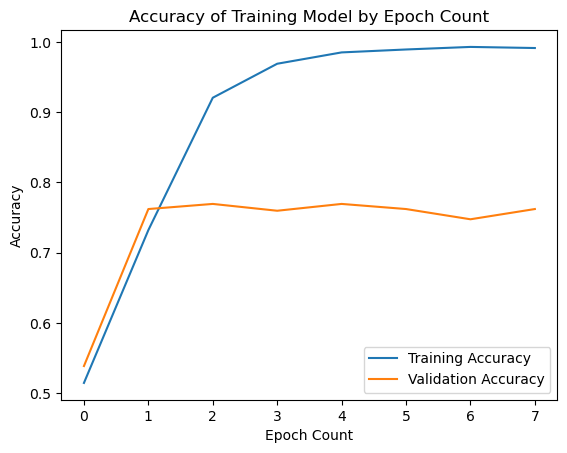

In [24]:
plt.plot(model_rslt.history['accuracy'],label="Training Accuracy")
plt.plot(model_rslt.history['val_accuracy'],label="Validation Accuracy")
plt.xlabel("Epoch Count")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy of Training Model by Epoch Count")
plt.show()

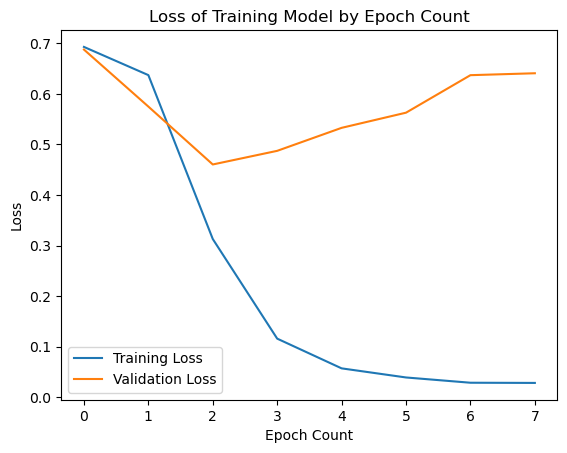

In [25]:
plt.plot(model_rslt.history['loss'],label="Training Loss")
plt.plot(model_rslt.history['val_loss'],label="Validation Loss")
plt.xlabel("Epoch Count")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss of Training Model by Epoch Count")
plt.show()

#### D4. Predictive Accuracy

The predictive accuracy of the model, when applied to the test data, has been calculated below. The model has an overall accuracy score of 0.7748, meaning it was able to accurately classify 77.48% of the test data.

In [26]:
# Create predictions vs. test data
y_pred = model.predict(X_test_pad_revs)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step


In [27]:
# Evalute the model vs. test data
model.evaluate(X_test_pad_revs, y_test)

13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7748 - loss: 0.6718 


[0.671769380569458, 0.7748184204101562]

[[159  46]
 [ 47 161]]


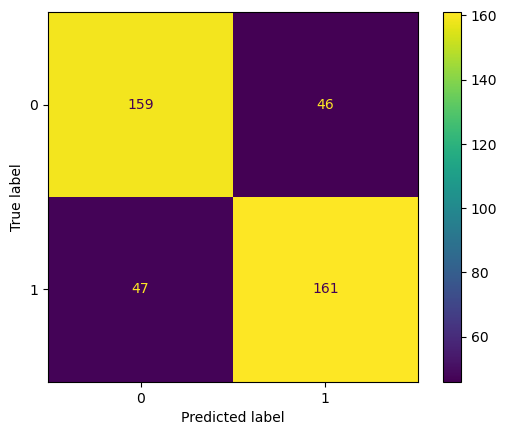

In [28]:
# Round y_pred to nearest integers
y_pred_rint = np.rint(y_pred)

# Generate confusion matrix to show acccurate and inaccurate predictions
cnfmtrx = confusion_matrix(y_test,y_pred_rint)
print(cnfmtrx)

disp = ConfusionMatrixDisplay(confusion_matrix=cnfmtrx)

disp.plot()
plt.show()

The confusion matrix for this model has been printed above. Going clockwise from the upper left, these numbers represent:

1. The number of negative observations correctly classified as negative by the model;
2. The number of negative observations incorrectly classified as positive by the model;
3. The number of positive observations correctly classified as positive by the model;
4. The number of positive observations incorrectly classified as negative by the model.

The model correctly classified 159 of the 205 total negative observations, or a roughly 77.56% success rate when classifying negative observations. It also correctly classified 161 of the 208 total positive observations, for a success rate of around 77.4%. The overall predictive accuracy of the model is around 77.48%.

### Part V: Summary and Recommendations

#### E. Code

The neural network model has been exported and submitted alongside this analysis, as "NN_SentimentAnalysis.h5"

In [ ]:
# Export NN model
model.save("NN_SentimentAnalysis.h5")

#### F. Functionality

The neural network trained here was built using an input dataset of 2748 customer reviews, each of them labelled with an associated "sentiment" score of 0 or 1 - indicating a negative or positive review, respectively. The neural network used natural language processing (NLP) to analyze the customer reviews in an attempt to determine the sentiment of these reviews. Success of the NN was measured by comparing the predicted label versus the actual label assigned to each review in the dataset. In terms of network architecture, the NN contains five layers, including the embedding layer, a flattening later, and three dense layers. The model is sequential - the linear stack of layers is grouped into the model (TensorFlow documentation, 2024). Each of these layers operates on the input data and passes the resulting output on to the next layer. 

The embedding layer converts the high-dimensional input data into a lower-dimensional space; this helps the model work with complex data in a simplified way (GeeksForGeeks, 2025). The flatten layer "flattens" the data, outputting a one-dimensional vector that can be then passed on to the dense layers. The dense layers analyse the data to learn patterns from it (ApX Machine Learning, 2026). The final layer of this model outputs a value of 0 or 1, indicating a negative or positive review. The activation functions used in this model are ReLU, or Rectified Linear Unit; the final layer uses the sigmoid activation function. The sigmoid function is appropriate for use in binary classification scenarios such as this, and can allow the model to more accurately incorporate non-linearity into the model (Vishwakarma, 2024). Each layer has a decreasing number of nodes; the embedding layer has 120, and the subsequent dense layers have 60, 30, and finally, 1.

The loss function used in this neural network is binary cross-entropy, which measures the difference between the actual labels of the observations and their predicted probabilities. Binary cross-entropy is commonly used in binary classifiers like the one created as part of this analysis (Godoy, 2018). The optimizer utilized here is Adaptive Moment Estimation ("Adam"), which is widely used for deep learning applications due to its efficiency (GeeksForGeeks, 2025; Keras 3 API documentation, n.d.).

When run against test data, the model accurately classifies 77.48% of all reviews. This model can be said to have a moderate level of success at performing sentiment analysis, but still did not accurately classify 22.52% of the test reviews. The research question posed earlier in this analysis was: "Can a neural network model be implemented to successfully evaluate customer review from various internet services, with the specific goal of determining whether a review is positive or negative based on the text contents of the reviews?" Based on the functionality of this model, the answer to this question appears to be, "somewhat." The model appears to be able to correctly identify the sentiment of reviews in the test data for the majority of cases, but still produces an inaccurate classification just over 22% of the time. This model has decent predictive accuracy, but it is not perfect.

#### G. Recommendations

The neural network trained here has around a 77.48% accuracy when asked to classify reviews into negative or positive labels. While this model performs generally well, it lacks a level of accuracy that I would consider appropriate for use in a production environment. My recommendation for the business would be to continue to build on and improve this model before using this to evaluate customer sentiment based on reviews, survey results, or other types of feedback received in text or natural language formats. I believe that the next course of action should be to re-train the model using a larger dataset of reviews in an attempt to improve its predictive accuracy, and perhaps further optimizing the model by introducing more layers and nodes.

### Part VI: Reporting

#### H. Reporting

As required by part H of the rubric, this analysis was performed in a Jupyter notebook environment.

#### I. Sources of Third-Party Code

NLTK Documentation. *nltk.tokenize.word_tokenize.* Jan 2 2023. https://www.nltk.org/api/nltk.tokenize.word_tokenize.html

TensorFlow Documentation. *tf.keras.callbacks.EarlyStopping* June 7 2024. https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping

TensorFlow Documentation. *tf.keras.utils.pad_sequences* June 7 2024. https://www.tensorflow.org/api_docs/python/tf/keras/utils/pad_sequences

TensorFlow Documentation. *tf.keras.preprocessing.text.Tokenizer.* June 7 2024. https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/text/Tokenizer

#### J. Sources

Arora, Sahil. *Natural Language Processing (NLP) Part 5:Understanding RNNs (Recurrent Neural Networks)* Aug 8 2025. https://medium.com/@sahilarora240792/natural-language-processing-nlp-part-5-understanding-rnns-recurrent-neural-networks-6a3d671968bf

ApX Machine Learning. Flattening and Dense Layers in CNNs. 2026. https://keras.io/api/layers/reshaping_layers/flatten/

Brownlee, Jason. *How to Configure the Number of Layers and Nodes in a Neural Network.* Machine Learning Mastery. August 6 2019. https://machinelearningmastery.com/how-to-configure-the-number-of-layers-and-nodes-in-a-neural-network/

GeeksForGeeks. *Choosing the Right Activation Function for Your Neural Network.* July 23 2025. https://www.geeksforgeeks.org/deep-learning/choosing-the-right-activation-function-for-your-neural-network/

Godoy, Daniel. *Understanding binary cross-entropy / log loss: a visual explanation.* Towards Data Science. November 21 2018. https://towardsdatascience.com/understanding-binary-cross-entropy-log-loss-a-visual-explanation-a3ac6025181a/

Keras 3 API documentation. *Adam*. Accessed April 5 2026. https://keras.io/api/optimizers/adam/

Raheja, Sakshi.*Train-Test-Validation Split in 2026*. AnalyticsVidhya, January 6, 2026. https://www.analyticsvidhya.com/blog/2023/11/train-test-validation-split/

PythonSpot. *NLTK Stop Words.* Accessed April 5 2026. https://pythonspot.com/nltk-stop-words/

GeeksForGeeks. *ReLU Activation Function in Deep Learning.* July 23 2025. https://www.geeksforgeeks.org/deep-learning/relu-activation-function-in-deep-learning/

GeeksForGeeks. *RNN for Text Classifications in NLP.* July 19 2025. https://www.geeksforgeeks.org/nlp/rnn-for-text-classifications-in-nlp/

Sohail, Saad. *Understanding Padding in NLP: Types and When to Use Them.* Medium.com, November 2 2024. https://saadsohail5104.medium.com/understanding-padding-in-nlp-types-and-when-to-use-them-bacae6cae401

TensorFlow documentation. *tf.keras.Sequential.* June 7 2024. https://www.tensorflow.org/api_docs/python/tf/keras/Sequential

Vishwakarma, Swapnil. How to Understand Sigmoid Function in Artificial Neural Networks? Analytics Vidhya, Dec 9 2024. https://www.analyticsvidhya.com/blog/2023/01/why-is-sigmoid-function-important-in-artificial-neural-networks/

GeeksForGeeks. *What is Embedding Layer?* July 23 2025. https://www.geeksforgeeks.org/deep-learning/what-is-embedding-layer/

GeeksForGeeks. *What is Tokenization in Natural Language Processing (NLP)?* July 23 2025. https://www.geeksforgeeks.org/nlp/tokenization-in-natural-language-processing-nlp/